[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Calidad de datos: duplicados e inconsistencias.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo I: *Datos y su calidad*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se presentará la lista de verificación de calidad que se usará en todo el curso, se detectarán y resolverán duplicados exactos y por llave, y se corregirán inconsistencias de texto, categorías, rangos imposibles, códigos centinela y unidades.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* **Ejercicio básico:** lo que todos deben dominar.
* **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

Los métodos de limpieza (`isna`, `notna`, `fillna`, `interpolate`, `dropna`, `duplicated`, `drop_duplicates`, …) se explican uno por uno en [py311 · 20 Limpieza y datos faltantes](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb), y el accesor `.str` en [py311 · 23 El accesor `str` de *pandas*](https://github.com/PythonistaMX/py311/blob/main/23_el_accesor_str_de_pandas.ipynb). Aquí se usan sin repasarlos a detalle: este *notebook* se dedica a **decidir** qué hacer con cada problema de calidad y a medir las consecuencias.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3. Allá las columnas de texto aparecen como `object` y se usa `inplace=True`; aquí el texto es `str` y se **reasigna** (`df["col"] = df["col"].fillna(...)`) o se usa `df.loc[...] = ...`, como se explicó en la sección 1.1 de `03_pandas_3_esencial.ipynb`.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)

* La siguiente celda leerá `penguins` y `titanic` y mostrará su forma.

In [2]:
pinguinos = pd.read_csv(os.path.join(DATA, "penguins.csv"))
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((344, 7), (891, 15))

---
## 1. Repaso y lista de verificación de calidad.

En `06_diccionario_de_datos.ipynb` se construyó el diccionario de datos y se vio que `penguins` tiene faltantes. Hoy se auditarán con orden. Esta es la **lista de verificación** que se usará en todo el curso:

| # | Pregunta | Herramientas |
|---|---|---|
| 1 | ¿Forma y tipos correctos? | `shape`, `info`, `dtypes` |
| 2 | ¿Hay una llave? ¿Es única? | `duplicated(subset=...)`, `nunique` |
| 3 | ¿Filas duplicadas exactas? | `duplicated()`, `drop_duplicates()` |
| 4 | ¿Categorías consistentes? | `value_counts(dropna=False)`, `str.strip`, `str.lower` |
| 5 | ¿Valores en rangos posibles? ¿Unidades homogéneas? | `describe`, `between`, reglas de dominio |
| 6 | ¿Cuántos faltantes, dónde y por qué? | `isna().sum()`, patrones por grupo |
| 7 | ¿Qué decisión se toma y cómo afecta? | comparar antes y después |

**Nota:** nunca se limpia "en silencio". Cada decisión se **documenta** y se **cuantifica**: cuántas filas afecta y cómo cambia el resultado.

### Ejercicio 1 · Perfil rápido reutilizable.

**🎯 Objetivo:** escribir una función de auditoría que sirva para cualquier *dataset*. **Qué se espera aprender:** a reunir en una tabla tipo, faltantes y valores únicos, el primer vistazo de la lista de verificación.

Escribe una función `perfil_rapido(df)` que devuelva un *dataframe* con una fila por columna y las columnas `dtype`, `n_faltantes`, `pct_faltantes` (0 a 100, con 1 decimal), `n_unicos` y `ejemplo` (el primer valor no nulo). Pruébala con `pinguinos` y con `titanic`. Te servirá en el resto del curso.

* La siguiente celda muestra una solución posible.

In [3]:
def perfil_rapido(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_faltantes": df.isna().sum(),
        "pct_faltantes": (df.isna().mean() * 100).round(1),
        "n_unicos": df.nunique(dropna=True),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })

perfil_rapido(pinguinos)

,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
species,str,0,0.0,3,Adelie
island,str,0,0.0,3,Torgersen
bill_length_mm,float64,2,0.6,164,39.1
bill_depth_mm,float64,2,0.6,80,18.7
flipper_length_mm,float64,2,0.6,55,181.0
body_mass_g,float64,2,0.6,94,3750.0
sex,str,11,3.2,2,MALE


* La siguiente celda aplicará `perfil_rapido` a `titanic`, ordenado por porcentaje de faltantes.

In [4]:
perfil_rapido(titanic).sort_values("pct_faltantes", ascending=False) if perfil_rapido(titanic) is not None else None

,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
deck,str,688,77.2,7,C
age,float64,177,19.9,88,22.0
embarked,str,2,0.2,3,S
embark_town,str,2,0.2,3,Southampton
sex,str,0,0.0,2,male
pclass,int64,0,0.0,3,3
survived,int64,0,0.0,2,0
fare,float64,0,0.0,248,7.25
parch,int64,0,0.0,7,0
sibsp,int64,0,0.0,7,1


---
## 2. Duplicados: exactos y por llave.

* **Duplicado exacto:** toda la fila se repite. Suele deberse a cargas repetidas o *joins* mal hechos.
* **Duplicado por llave:** la llave (por ejemplo, `id`) se repite aunque otras columnas difieran. Es más delicado: hay que **decidir qué registro es el bueno**.

Repaso: `df.duplicated()` marca cada fila que **ya apareció antes** (`keep=False` marca todas las copias) y `drop_duplicates` las elimina; el detalle está en [py311 · 20](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb). La parte difícil no es el método sino la **política**: qué registro se conserva y por qué.

**¿Por qué los duplicados importan en el EDA?** Un registro repetido cuenta dos veces en cada conteo, media y proporción, y con un *join* mal hecho puede multiplicar filas sin aviso. Antes de describir hay que saber **qué representa cada fila** (la unidad de observación) y verificar que cada unidad aparezca una sola vez. La **llave** es la columna o combinación de columnas que identifica a cada unidad.

* La siguiente celda creará un pequeño registro de inscripciones al curso.

In [5]:
inscripciones = pd.DataFrame({
    "id_alumno": [101, 102, 103, 102, 104, 105, 105],
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Iván", "Sofía", "Sofía"],
    "correo": ["ana@x.mx", "luis@x.mx", "marta@x.mx", "luis@x.mx", "ivan@x.mx", "sofia@x.mx", "sofia.r@x.mx"],
    "fecha": ["2025-03-01", "2025-03-02", "2025-03-02", "2025-03-02", "2025-03-05", "2025-03-06", "2025-03-09"],
})
inscripciones.duplicated().sum(), inscripciones.duplicated(subset=["id_alumno"]).sum()

(np.int64(1), np.int64(2))

* La siguiente celda mostrará todas las filas cuyo `id_alumno` está repetido.

In [6]:
inscripciones[inscripciones.duplicated(subset=["id_alumno"], keep=False)]

,id_alumno,nombre,correo,fecha
1,102,Luis,luis@x.mx,2025-03-02
3,102,Luis,luis@x.mx,2025-03-02
5,105,Sofía,sofia@x.mx,2025-03-06
6,105,Sofía,sofia.r@x.mx,2025-03-09


* La siguiente celda aplicará una política explícita: conservar el registro **más reciente** de cada alumno.

In [7]:
(
    inscripciones
    .sort_values("fecha")
    .drop_duplicates(subset=["id_alumno"], keep="last")
    .sort_values("id_alumno")
)

,id_alumno,nombre,correo,fecha
0,101,Ana,ana@x.mx,2025-03-01
3,102,Luis,luis@x.mx,2025-03-02
2,103,Marta,marta@x.mx,2025-03-02
4,104,Iván,ivan@x.mx,2025-03-05
6,105,Sofía,sofia.r@x.mx,2025-03-09


**Interpretación:** de 7 filas quedan 5 alumnos: se eliminó la fila idéntica de Luis y, de Sofía, se conservó el registro más reciente (con el correo corregido). Otra política (el registro más antiguo, el más completo) daría otro correo. Lo importante es que la regla quede **escrita** y se pueda repetir.

### ¿Todo duplicado exacto es un error? El caso `titanic`.

* La siguiente celda contará las filas de `titanic` idénticas a otra anterior y su proporción.

In [8]:
n_duplicados = titanic.duplicated().sum()
n_duplicados, round(n_duplicados / len(titanic), 3)

(np.int64(107), np.float64(0.12))

**Interpretación:** 107 filas (12%) son idénticas a otra. Pero `titanic` no tiene nombre ni número de boleto: dos pasajeros distintos con la misma clase, sexo, edad y tarifa son indistinguibles. **Error común que se evita:** eliminar estos "duplicados" sin pensar, lo que borraría pasajeros reales. Sin una llave, un duplicado exacto no prueba que sea un error.

* La siguiente celda mostrará algunos de esos duplicados.

In [9]:
titanic[titanic.duplicated(keep=False)].sort_values(["class", "sex", "age"]).head(6)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
369,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
641,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
443,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True
635,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True


`titanic` **no tiene llave** (no hay nombre ni número de boleto). Dos hombres de tercera clase, sin edad registrada, que embarcaron en Southampton y pagaron la misma tarifa pueden ser **personas distintas** con los mismos atributos (hay 38 filas así, aunque la tabla anterior solo muestra las primeras 6 duplicadas). De hecho, de los 107 duplicados, 86 son de tercera clase y 71 no tienen edad: las filas repetidas aparecen justo donde hay menos datos para distinguir a una persona de otra. Borrar esas filas eliminaría pasajeros reales y sesgaría el análisis.

**Nota:** sin una llave, un duplicado exacto es solo **sospechoso**, no necesariamente un error. Se decide con conocimiento del origen de los datos.

### Un *dataset* "sucio" para practicar.

La función `ensuciar_pinguinos` toma `penguins` y le introduce, con semilla fija, problemas típicos del mundo real: una llave `id_muestra`, duplicados, texto inconsistente, unidades mezcladas y códigos imposibles. **No es necesario estudiarla**: el trabajo consiste en *descubrir* los problemas como si no se supiera qué tiene.

* La siguiente celda definirá `ensuciar_pinguinos`.

In [10]:
def ensuciar_pinguinos(df, semilla=401):
    r = np.random.default_rng(semilla)
    d = df.copy().reset_index(drop=True)
    d.insert(0, "id_muestra", [f"P{i:04d}" for i in range(1, len(d) + 1)])
    con_medidas = d.index[d["body_mass_g"].notna()]

    variantes = {"Adelie": ["adelie", " Adelie", "ADELIE", "Adelie "],
                 "Gentoo": ["gentoo", "Gentoo ", "Gentoo penguin"],
                 "Chinstrap": ["chinstrap", "Chinstrap ", "Chinstarp"]}
    for i in r.choice(len(d), 30, replace=False):
        d.loc[i, "species"] = str(r.choice(variantes[d.loc[i, "species"]]))
    i = r.choice(len(d), 20, replace=False)
    d.loc[i, "island"] = d.loc[i, "island"].str.lower() + " "
    i = r.choice(d.index[d["sex"].notna()], 25, replace=False)
    opciones_sexo = {"MALE": ["M", "male", "Male"], "FEMALE": ["F", "female", "Female"]}
    d.loc[i, "sex"] = d.loc[i, "sex"].map(lambda s: str(r.choice(opciones_sexo[s])))
    d.loc[r.choice(d.index[d["sex"].isna()], 3, replace=False), "sex"] = "."

    permutacion = r.permutation(con_medidas)
    i_kg, i_aleta, i_pico, i_recaptura = permutacion[:8], permutacion[8:12], permutacion[12:14], permutacion[14:18]
    d.loc[i_kg, "body_mass_g"] = d.loc[i_kg, "body_mass_g"] / 1000
    d.loc[i_aleta, "flipper_length_mm"] = [-999, -999, 0, 2100]
    d.loc[i_pico, "bill_length_mm"] = 999

    exactos = d.sample(6, random_state=semilla)
    recaptura = d.loc[i_recaptura].assign(body_mass_g=lambda x: x["body_mass_g"] + 75)
    return pd.concat([d, exactos, recaptura]).sample(frac=1, random_state=semilla).reset_index(drop=True)

* La siguiente celda creará `sucio` y mostrará sus primeras filas.

In [11]:
sucio = ensuciar_pinguinos(pinguinos)
sucio.head()

,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,P0176,Chinstrap,Dream,50.6,19.4,193.0,3800.0,MALE
1,P0096,Adelie,Dream,40.8,18.9,208.0,4300.0,male
2,P0225,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
3,P0324,Gentoo,biscoe,49.1,15.0,228.0,5500.0,MALE
4,P0299,Gentoo,Biscoe,45.2,13.8,215.0,4750.0,FEMALE


### Ejercicio 2 · Duplicados en `sucio`.

**🎯 Objetivo:** distinguir duplicados exactos de duplicados por llave. **Qué se espera aprender:** que eliminar duplicados exactos no basta: hay que revisar la llave y decidir qué registro conservar.

1. ¿Cuántos duplicados **exactos** hay? Elimínalos y guarda el resultado en `sin_dup`.
2. En `sin_dup`, ¿cuántos `id_muestra` siguen **repetidos**? Muestra todas las filas de esos ids, ordenadas por `id_muestra`. ¿En qué columna difieren?

* La siguiente celda muestra una solución posible.

In [12]:
sin_dup = sucio.drop_duplicates()
repetidos = sin_dup.duplicated(subset=["id_muestra"], keep=False)
sucio.duplicated().sum(), len(sucio), len(sin_dup), sin_dup.loc[repetidos, "id_muestra"].nunique()

(np.int64(6), 354, 348, 4)

* La siguiente celda mostrará las filas con `id_muestra` repetido (requiere `sin_dup`).

In [13]:
sin_dup[sin_dup.duplicated(subset=["id_muestra"], keep=False)].sort_values("id_muestra") if sin_dup is not None else None

,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
79,P0039,Adelie,Dream,37.6,19.3,181.0,3375.0,FEMALE
155,P0039,Adelie,Dream,37.6,19.3,181.0,3300.0,FEMALE
210,P0114,Adelie,Biscoe,42.2,19.5,197.0,4350.0,MALE
296,P0114,Adelie,Biscoe,42.2,19.5,197.0,4275.0,MALE
42,P0120,Adelie,Torgersen,41.1,18.6,189.0,3400.0,MALE
161,P0120,Adelie,Torgersen,41.1,18.6,189.0,3325.0,MALE
78,P0151,Adelie,Dream,36.0,17.1,187.0,3700.0,FEMALE
351,P0151,Adelie,Dream,36.0,17.1,187.0,3775.0,FEMALE


**✅ Respuesta sugerida:**

Hay 6 duplicados exactos (de 354 a 348 filas). Quedan 4 `id_muestra` repetidos que difieren en `body_mass_g`: probablemente son "re-capturas" del mismo individuo con otra masa, o errores de captura. Los datos no permiten saber cuál de las dos; por eso hace falta una política escrita (reto 1).

### Reto 1 · Resolver duplicados por llave con una regla.

**🎯 Objetivo:** convertir una política de duplicados en código explícito. **Qué se espera aprender:** a dejar por escrito y de forma reproducible qué registro se conserva y por qué.

Escribe una función `columnas_en_conflicto(df, llave)` que, para cada valor de la llave repetido, liste **qué columnas** tienen valores distintos. Luego aplica una política: conservar la **primera aparición en el archivo** de cada `id_muestra` y guarda el resultado en `sin_dup_llave`. ¿Qué otra política sería razonable?

* La siguiente celda muestra una solución posible.

In [14]:
def columnas_en_conflicto(df, llave):
    repetidas = df[df.duplicated(subset=[llave], keep=False)]
    conflictos = repetidas.groupby(llave).nunique(dropna=False).gt(1)
    return conflictos.apply(lambda fila: list(fila.index[fila]), axis=1)

sin_dup_llave = sin_dup.drop_duplicates(subset=["id_muestra"], keep="first")
columnas_en_conflicto(sin_dup, "id_muestra"), len(sin_dup_llave), sin_dup_llave["id_muestra"].is_unique

(id_muestra
 P0039    [body_mass_g]
 P0114    [body_mass_g]
 P0120    [body_mass_g]
 P0151    [body_mass_g]
 dtype: object,
 344,
 True)

**✅ Respuesta sugerida:**

Otras políticas razonables: promediar las mediciones numéricas del mismo individuo o quedarse con el registro que tenga menos faltantes. Lo importante es que la regla sea explícita y se documente.

**💡 Ideas clave de la sección 2:**
* Primero se define la unidad de observación y su llave.
* Duplicados exactos: se eliminan si hay llave que lo justifique; sin llave pueden ser observaciones legítimas.
* Duplicados por llave: se resuelven con una política explícita y documentada.

---
## 3. Inconsistencias.

### 3.1 Texto y categorías.

El primer síntoma aparece con `value_counts(dropna=False)`: la misma categoría escrita de varias formas.

**Concepto: una categoría, muchas escrituras.** Para *pandas*, `"Adelie"`, `"adelie"` y `" Adelie"` son tres valores distintos. Cada variante parte un grupo en varios y altera conteos, proporciones y comparaciones por grupo. `value_counts(dropna=False)` es la herramienta para verlas todas, incluidos los faltantes.

* La siguiente celda mostrará las variantes de `species`, `island` y `sex`.

In [15]:
sucio["species"].value_counts(dropna=False), sucio["island"].value_counts(dropna=False), sucio["sex"].value_counts(dropna=False)

(species
 Adelie            146
 Gentoo            116
 Chinstrap          61
 Adelie              7
 Gentoo              5
 chinstrap           5
  Adelie             4
 Gentoo penguin      2
 gentoo              2
 adelie              2
 Chinstarp           2
 Chinstrap           1
 ADELIE              1
 Name: count, dtype: int64,
 island
 Biscoe        161
 Dream         123
 Torgersen      49
 biscoe         12
 dream           5
 torgersen       4
 Name: count, dtype: int64,
 sex
 FEMALE    161
 MALE      156
 M           9
 NaN         8
 male        7
 F           4
 .           3
 Female      3
 female      2
 Male        1
 Name: count, dtype: int64)

**Interpretación:** `species` aparece con 13 escrituras distintas (mayúsculas, espacios, sufijos como "penguin" y la errata "Chinstarp") para solo 3 especies reales. Si no se unifican, el grupo Adelie aparecería partido en 5 filas de la tabla.

**Nota:** en *pandas* 3 estas columnas son de tipo `str`, así que los métodos del accesor `.str` funcionan directamente y los faltantes se conservan como `NaN`.

* La siguiente celda unificará espacios y mayúsculas de `species`: quitará los espacios sobrantes (`strip`) y pasará todo a minúsculas (`lower`).

In [16]:
especie_normalizada = sucio["species"].str.strip().str.lower()
especie_normalizada.value_counts()

species
adelie            160
gentoo            123
chinstrap          67
gentoo penguin      2
chinstarp           2
Name: count, dtype: int64

**Interpretación:** `str.strip().str.lower()` resuelve las variantes de formato (de 13 a 5 escrituras), pero no las de contenido: "gentoo penguin" y "chinstarp" necesitan un **mapa explícito**.

* La siguiente celda mapeará las variantes a la categoría canónica; lo que no esté en el mapa quedará como `NaN` y habría que revisarlo.

In [17]:
mapa_especie = {"adelie": "Adelie", "gentoo": "Gentoo", "gentoo penguin": "Gentoo",
                "chinstrap": "Chinstrap", "chinstarp": "Chinstrap"}
especie_limpia = especie_normalizada.map(mapa_especie)
especie_limpia.isna().sum(), especie_limpia.value_counts()

(np.int64(0),
 species
 Adelie       160
 Gentoo       125
 Chinstrap     69
 Name: count, dtype: int64)

### 3.2 Rangos imposibles, códigos centinela y unidades.

`describe()` y un poco de conocimiento del dominio delatan los problemas: una aleta no mide −999 mm ni 2.1 m, y un pingüino no pesa 4.2 g.

**Concepto: valores imposibles.** Hay tres fuentes típicas: **códigos centinela** (−999 o 999 para "sin dato"), **unidades mezcladas** (kg y g en la misma columna) y **errores de captura** (un dígito de más). Se detectan comparando el mínimo y el máximo con lo que es físicamente posible, y se corrigen solo cuando la causa es evidente; si no, se marcan como faltantes.

* La siguiente celda mostrará el resumen numérico de `sucio`.

In [18]:
sucio.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,352.0,49.224148,72.102707,32.1,39.175,44.05,48.5,999.0
bill_depth_mm,352.0,17.172727,1.959445,13.1,15.675,17.30,18.7,21.5
flipper_length_mm,352.0,198.639205,137.062208,-999.0,190.000,197.00,213.0,2100.0
body_mass_g,352.0,4097.111009,1034.794899,2.9,3500.000,4000.00,4750.0,6300.0


**Interpretación:** el mínimo de la aleta es −999 mm y el máximo del pico, 999 mm: códigos centinela. La masa mínima de 2.9 g es imposible para un pingüino adulto. Por eso la desviación estándar del pico (72 mm) es absurda: bastan **dos** valores imposibles (los dos 999 mm) para inflarla de unos 5 mm a 72 mm y subir la media de 43.8 a 49.2 mm, mientras que la mediana (el valor del medio) casi no cambia: 43.9 contra 44.05 mm. Es la razón por la que la mediana se considera más **resistente** a los errores.

* La siguiente celda listará las masas sospechosamente pequeñas (¿capturadas en kg?).

In [19]:
sucio.loc[sucio["body_mass_g"] < 100, "body_mass_g"].sort_values().to_list()

[2.9, 3.4, 3.5, 3.7, 3.7, 3.775, 3.9, 4.1, 4.1]

**Interpretación:** son 9 valores de 8 pingüinos (`P0219`, con 4.1, aparece dos veces porque es un duplicado exacto que aún no se ha quitado). Todos están entre 2.9 y 4.1, justo el rango de masas reales **en kilogramos**. La explicación más probable es una captura en kg; multiplicar por 1,000 es una corrección justificada, y hay que reportar cuántos valores se cambiaron.

* La siguiente celda graficará el histograma de la masa en escala logarítmica (cada marca del eje vale 10 veces la anterior, así caben juntos los valores chicos y los grandes). Se verán dos "montañas": una con las masas en kg y otra con las masas en g.

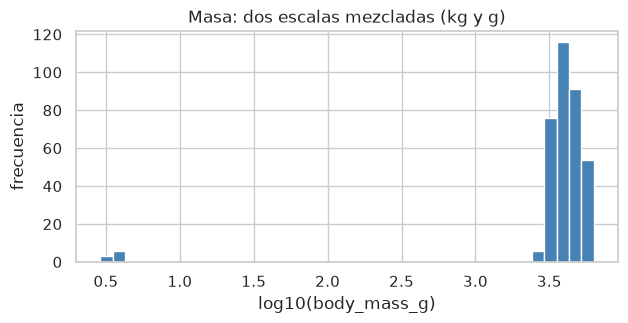

In [20]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(sucio["body_mass_g"].dropna()), bins=40, color="steelblue")
ax.set(xlabel="log10(body_mass_g)", ylabel="frecuencia", title="Masa: dos escalas mezcladas (kg y g)")
plt.show()

**Criterios típicos** (siempre documentados):
* **Códigos centinela** (`-999`, `0`, `9999`, `"."`, `"NA"`): convertirlos a `NaN`.
* **Unidades:** si la regla es inequívoca (masa < 100 ⇒ estaba en kg), convertir; si no, marcar y consultar.
* **Fuera de rango plausible:** a `NaN` si es imposible; si solo es raro, **no** se toca aquí (eso es un valor atípico: raro, pero posible, y se estudia en `12_valores_atipicos_y_transformaciones.ipynb`).

### Ejercicio 3 · Unifica las categorías.

**🎯 Objetivo:** unificar variantes de texto con un mapa explícito. **Qué se espera aprender:** a unificar sin perder valores en silencio y a verificar los conteos antes y después.

A partir de `sin_dup` sin duplicados por llave (`sin_dup.drop_duplicates(subset=["id_muestra"])`), crea `limpio` con `species`, `island` y `sex` unificadas en `Adelie/Chinstrap/Gentoo`, `Biscoe/Dream/Torgersen` y `Male/Female` (con `"."` convertido a `NaN`). Verifica con `value_counts(dropna=False)` que no queden variantes, y comprueba que no se perdieron valores en silencio: `map` convierte en `NaN` todo lo que no está en el mapa, así que los faltantes de `sex` después de unificar deben ser **exactamente** los que ya había más los `"."` convertidos.

* La siguiente celda muestra una solución posible.

In [21]:
mapa_sexo = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
limpio = sin_dup.drop_duplicates(subset=["id_muestra"]).assign(
    species=lambda d: d["species"].str.strip().str.lower().map(mapa_especie),
    island=lambda d: d["island"].str.strip().str.title(),
    sex=lambda d: d["sex"].str.strip().str.lower().map(mapa_sexo),
)
sexo_original = sin_dup.drop_duplicates(subset=["id_muestra"])["sex"]
verificacion_sexo = {"faltantes antes": int(sexo_original.isna().sum()),
                     "puntos convertidos": int((sexo_original.str.strip() == ".").sum()),
                     "faltantes después": int(limpio["sex"].isna().sum())}
[limpio[c].value_counts(dropna=False).to_dict() for c in ["species", "island", "sex"]], verificacion_sexo

([{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68},
  {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52},
  {'Male': 168, 'Female': 165, nan: 11}],
 {'faltantes antes': 8, 'puntos convertidos': 3, 'faltantes después': 11})

### Ejercicio 4 · Rangos y unidades.

**🎯 Objetivo:** detectar y corregir códigos centinela y unidades mezcladas. **Qué se espera aprender:** a usar reglas del dominio (rangos plausibles) y a cuantificar cada corrección.

En `limpio`:
1. Convierte a gramos las masas que están en kg (valores < 100).
2. Pon en `NaN` las aletas fuera de 150 a 250 mm y los picos fuera de 30 a 65 mm.
3. Reporta **cuántos valores** cambió cada regla y compara `describe()` antes y después.

**Nota:** con *Copy-on-Write* la forma correcta de modificar `limpio` es `limpio.loc[mascara, "columna"] = valor`.

* La siguiente celda muestra una solución posible.

In [22]:
columnas_num = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
antes = limpio[columnas_num].describe().T

en_kg = limpio["body_mass_g"] < 100
aleta_mala = limpio["flipper_length_mm"].notna() & ~limpio["flipper_length_mm"].between(150, 250)
pico_malo = limpio["bill_length_mm"].notna() & ~limpio["bill_length_mm"].between(30, 65)

limpio.loc[en_kg, "body_mass_g"] = limpio.loc[en_kg, "body_mass_g"] * 1000
limpio.loc[aleta_mala, "flipper_length_mm"] = np.nan
limpio.loc[pico_malo, "bill_length_mm"] = np.nan

despues = limpio[columnas_num].describe().T
cambios = {"kg a g": int(en_kg.sum()), "aletas a NaN": int(aleta_mala.sum()), "picos a NaN": int(pico_malo.sum())}
cambios, pd.concat({"antes": antes[["min", "mean", "max"]], "después": despues[["min", "mean", "max"]]}, axis=1).round(1)

({'kg a g': 8, 'aletas a NaN': 4, 'picos a NaN': 2},
                    antes                 después                
                      min    mean     max     min    mean     max
 bill_length_mm      32.1    49.5   999.0    32.1    43.9    59.6
 flipper_length_mm -999.0   198.8  2100.0   172.0   200.9   231.0
 body_mass_g          2.9  4117.8  6300.0  2700.0  4202.4  6300.0)

### Reto 2 · Validador de reglas.

**🎯 Objetivo:** automatizar la verificación de rangos. **Qué se espera aprender:** a escribir reglas de calidad que se pueden volver a ejecutar después de cada cambio.

Escribe `validar(df, reglas)` donde `reglas` es un diccionario `{columna: (minimo, maximo)}` y devuelve un *dataframe* con, por columna, `n_fuera_de_rango`, `pct_fuera_de_rango` y hasta 5 ejemplos. Reporta el porcentaje **sobre el total de filas** (incluidas las que no tienen dato en esa columna) y dilo así en el resultado: es la pregunta del denominador de `03_pandas_3_esencial.ipynb`. Aplícalo a `sucio` y a `limpio`. Este tipo de función es muy útil en cualquier auditoría.

* La siguiente celda muestra una solución posible.

In [23]:
def validar(df, reglas):
    filas = []
    for columna, (minimo, maximo) in reglas.items():
        serie = df[columna]
        fuera = serie.notna() & ~serie.between(minimo, maximo)
        filas.append({"columna": columna, "rango": f"[{minimo}, {maximo}]",
                      "n_fuera_de_rango": int(fuera.sum()),
                      "pct_fuera_de_rango": round(100 * fuera.mean(), 2),
                      "ejemplos": serie[fuera].head(5).tolist()})
    return pd.DataFrame(filas).set_index("columna")

reglas = {"bill_length_mm": (30, 65), "bill_depth_mm": (12, 23),
          "flipper_length_mm": (150, 250), "body_mass_g": (2500, 6500)}
validar(sucio, reglas)

,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",2,0.56,"[999.0, 999.0]"
bill_depth_mm,"[12, 23]",0,0.00,[]
flipper_length_mm,"[150, 250]",4,1.13,"[-999.0, 0.0, -999.0, 2100.0]"
body_mass_g,"[2500, 6500]",9,2.54,"[3.4, 3.775, 3.9, 4.1, 3.5]"


* La siguiente celda aplicará el validador a `limpio` (requiere el reto 2 y el ejercicio 4).

In [24]:
validar(limpio, reglas) if "validar" in globals() and limpio is not None else None

,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",0,0.0,[]
bill_depth_mm,"[12, 23]",0,0.0,[]
flipper_length_mm,"[150, 250]",0,0.0,[]
body_mass_g,"[2500, 6500]",0,0.0,[]


**💡 Ideas clave de la sección 3:**
* Unificar el texto (`strip`, `lower`) y después mapear variantes con un diccionario explícito; lo que no esté en el mapa se revisa.
* Rangos imposibles: centinelas, unidades mezcladas, errores de captura. Se corrige solo cuando la causa es evidente.
* Cada corrección se cuenta y se reporta.

---
## ✅ Cierre.

**Práctica (en Classroom):** terminar los ejercicios pendientes de este *notebook* y, si es posible, un reto.

**Siguiente *notebook*:** `08_valores_faltantes.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>